# Transformers — Notebook 02
## Mecanismo de atención aplicado a la serie de tiempo

**Idea central.** La atención responde a la pregunta *«¿en qué partes de la secuencia debo fijarme para producir esta salida?»*. Dada una **consulta** (query), compara su parecido con un conjunto de **claves** (keys) y devuelve un **promedio ponderado de los valores** (values), con pesos que suman 1:

$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

En una serie de tiempo la consulta representa **el momento desde el que se pronostica** y las claves/valores representan **los días del pasado**: los pesos α indican qué días del contexto influyen en la predicción. Este notebook implementa la atención en tres niveles:

1. **Atención no paramétrica en NumPy**: el pronóstico es un promedio de lo que ocurrió después de los episodios históricos más parecidos al actual (atención sin pesos entrenables).
2. **LSTM + atención aditiva (Bahdanau, 2015)**: capa de atención propia sobre los estados ocultos del LSTM.
3. **LSTM + atención de producto escalado (Luong / Vaswani)**: la misma función que usa el Transformer.

Se comparan con un **LSTM sin atención** (arquitectura recurrente tradicional) y con los modelos de referencia del Notebook 01.

In [1]:
import os, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
"""Utilidades de series de tiempo: carga, partición cronológica, escalado, ventanas, líneas base y métricas."""
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOOKBACK = 60          # días de contexto que ve el modelo
HORIZON = 7            # días a pronosticar
SPLITS = {"train": ("1981-01-01", "1986-12-31"), "val": ("1987-01-01", "1988-12-31"), "test": ("1989-01-01", "1990-12-31")}

for d in ("data", "figures", "results", "modelos"):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load_series(path: str = "data/daily-min-temperatures.csv") -> pd.Series:
    """Temperatura mínima diaria de Melbourne (°C), con frecuencia diaria completa."""
    if not os.path.exists(path):
        pd.read_csv(URL).to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["Date"])
    s = pd.to_numeric(df["Temp"], errors="coerce")
    s.index = df["Date"]
    full = s.asfreq("D")                       # inserta las fechas faltantes como NaN
    return full


def calendar_features(index: pd.DatetimeIndex) -> np.ndarray:
    """Codificación cíclica del día del año: (sin, cos). Evita el salto artificial 31-dic → 1-ene."""
    doy = index.dayofyear.values
    ang = 2 * np.pi * doy / 365.25
    return np.stack([np.sin(ang), np.cos(ang)], axis=1).astype("float32")


class Scaler:
    """Estandarización z-score ajustada SÓLO con el conjunto de entrenamiento."""
    def fit(self, x):
        self.mu, self.sigma = float(np.mean(x)), float(np.std(x)); return self
    def transform(self, x): return (np.asarray(x) - self.mu) / self.sigma
    def inverse(self, z): return np.asarray(z) * self.sigma + self.mu


def make_windows(values_z, feats, dates, start, end, lookback=LOOKBACK, horizon=HORIZON):
    """Ventanas deslizantes: X = [temp_z, sin, cos] de los `lookback` días previos,
    y = temp_z de los `horizon` días siguientes. Sólo se aceptan ventanas cuyo PRIMER día
    a pronosticar cae en [start, end] y cuyo último día objetivo no supera `end`
    (el contexto sí puede venir del periodo anterior, que ya es pasado conocido)."""
    X_in = np.concatenate([values_z[:, None], feats], axis=1).astype("float32")
    t0 = np.searchsorted(dates, np.datetime64(start)); t1 = np.searchsorted(dates, np.datetime64(end), side="right")
    X, Y, D, F = [], [], [], []
    for t in range(max(t0, lookback), t1 - horizon + 1):
        X.append(X_in[t - lookback:t]); Y.append(values_z[t:t + horizon])
        F.append(feats[t:t + horizon]); D.append(dates[t])
    return np.array(X), np.array(Y, dtype="float32"), np.array(F, dtype="float32"), np.array(D)


def prepare(lookback=LOOKBACK, horizon=HORIZON):
    """Pipeline completo: serie limpia, escalador y ventanas por partición."""
    s = load_series()
    n_missing = int(s.isna().sum())
    s = s.interpolate(limit_direction="both")
    dates = s.index.values
    tr_mask = (s.index >= SPLITS["train"][0]) & (s.index <= SPLITS["train"][1])
    scaler = Scaler().fit(s.values[tr_mask])
    z = scaler.transform(s.values).astype("float32")
    feats = calendar_features(s.index)
    data = {"series": s, "scaler": scaler, "n_missing": n_missing, "z": z, "feats": feats}
    for name, (a, b) in SPLITS.items():
        X, Y, F, D = make_windows(z, feats, dates, a, b, lookback, horizon)
        data[name] = {"X": X, "Y": Y, "F": F, "dates": D}
    return data


# ----------------------------------------------------------------------------- líneas base
def persistence(X):
    """Pronóstico ingenuo: los próximos días serán iguales al último observado."""
    return np.repeat(X[:, -1:, 0], HORIZON, axis=1)


def climatology_model(series: pd.Series, scaler: Scaler, window: int = 15):
    """Media por día del año en train (suavizada con media móvil circular). Devuelve f(fechas)->z."""
    tr = series[SPLITS["train"][0]:SPLITS["train"][1]]
    clim = tr.groupby(tr.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    ext = pd.concat([clim.iloc[-window:], clim, clim.iloc[:window]])
    smooth = ext.rolling(window, center=True).mean().iloc[window:-window]
    def predict(first_dates):
        out = []
        for d0 in pd.to_datetime(first_dates):
            days = pd.date_range(d0, periods=HORIZON, freq="D").dayofyear
            out.append(scaler.transform(smooth.loc[days].values))
        return np.array(out, dtype="float32")
    return predict, smooth


# ----------------------------------------------------------------------------- métricas
def metrics(y_true_z, y_pred_z, scaler: Scaler) -> dict:
    """MAE y RMSE en °C (global y por horizonte)."""
    yt, yp = scaler.inverse(y_true_z), scaler.inverse(y_pred_z)
    err = yp - yt
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "MAE_h": np.abs(err).mean(0).tolist(), "MAE_d1": float(np.abs(err[:, 0]).mean()),
            "MAE_d7": float(np.abs(err[:, -1]).mean())}


def save_json(obj, path):
    def conv(o):
        if isinstance(o, (np.floating, np.integer)): return o.item()
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=conv)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

In [3]:
"""Mecanismos de atención y bloques Transformer implementados desde cero en Keras 3 (backend TensorFlow).

Referencia: Vaswani et al. (2017), "Attention Is All You Need".
"""
import numpy as np
import tensorflow as tf
import keras
from keras import layers, ops


# ============================================================================ atención básica
def scaled_dot_product_attention(q, k, v, mask=None):
    """Attention(Q, K, V) = softmax(Q·Kᵀ / √d_k + máscara) · V      (ecuación 1 del paper)

    q: (..., Tq, d_k)  k: (..., Tk, d_k)  v: (..., Tk, d_v)
    mask: 1 = posición permitida, 0 = bloqueada; se suma -1e9 a las bloqueadas antes del softmax.
    Devuelve (salida (..., Tq, d_v), pesos de atención (..., Tq, Tk)).
    """
    d_k = ops.cast(ops.shape(k)[-1], q.dtype)
    scores = ops.matmul(q, ops.swapaxes(k, -1, -2)) / ops.sqrt(d_k)
    if mask is not None:
        scores = scores + (1.0 - ops.cast(mask, scores.dtype)) * -1e9
    weights = ops.softmax(scores, axis=-1)
    return ops.matmul(weights, v), weights


def causal_mask(T):
    """Máscara triangular inferior: la posición t sólo puede atender a posiciones ≤ t."""
    return np.tril(np.ones((T, T), dtype="float32"))


@keras.saving.register_keras_serializable(package="tst")
class AdditiveAttention(layers.Layer):
    """Atención aditiva de Bahdanau sobre los estados ocultos de un codificador recurrente.

    e_t = vᵀ tanh(W₁ h_t + W₂ s),  α = softmax(e),  c = Σ_t α_t h_t
    donde h_t son los estados del LSTM en cada día y s es el último estado (la "consulta").
    """
    def __init__(self, units=32, **kw):
        super().__init__(**kw); self.units = units
        self.W1 = layers.Dense(units, use_bias=False)
        self.W2 = layers.Dense(units, use_bias=True)
        self.v = layers.Dense(1, use_bias=False)

    def call(self, states, query):
        score = self.v(ops.tanh(self.W1(states) + ops.expand_dims(self.W2(query), 1)))   # (B, T, 1)
        alpha = ops.softmax(score, axis=1)
        context = ops.sum(alpha * states, axis=1)                                         # (B, units_lstm)
        return context, ops.squeeze(alpha, -1)

    def get_config(self):
        return {**super().get_config(), "units": self.units}


# ============================================================================ Transformer
@keras.saving.register_keras_serializable(package="tst")
class PositionalEncoding(layers.Layer):
    """Codificación posicional sinusoidal (sección 3.5 del paper):
    PE(pos, 2i) = sin(pos / 10000^(2i/d)),  PE(pos, 2i+1) = cos(pos / 10000^(2i/d)).
    Se SUMA al embedding: la atención por sí sola no conoce el orden temporal."""
    def __init__(self, max_len=512, d_model=32, **kw):
        super().__init__(**kw); self.max_len, self.d_model = max_len, d_model
        pos = np.arange(max_len)[:, None]
        i = np.arange(d_model)[None, :]
        angle = pos / np.power(10000.0, (2 * (i // 2)) / d_model)
        pe = np.zeros((max_len, d_model), dtype="float32")
        pe[:, 0::2], pe[:, 1::2] = np.sin(angle[:, 0::2]), np.cos(angle[:, 1::2])
        self.pe = pe

    def call(self, x):
        T = ops.shape(x)[1]
        return x + ops.convert_to_tensor(self.pe)[None, :T, :]

    def get_config(self):
        return {**super().get_config(), "max_len": self.max_len, "d_model": self.d_model}


@keras.saving.register_keras_serializable(package="tst")
class MultiHeadAttentionScratch(layers.Layer):
    """Multi-head attention (sección 3.2.2):
    MultiHead(Q,K,V) = Concat(head₁..head_h)·Wᴼ,   head_i = Attention(Q·Wᵢ^Q, K·Wᵢ^K, V·Wᵢ^V).
    Las h cabezas trabajan en paralelo en subespacios de dimensión d_k = d_model / h."""
    def __init__(self, d_model=32, num_heads=4, **kw):
        super().__init__(**kw)
        assert d_model % num_heads == 0, "d_model debe ser divisible por num_heads"
        self.d_model, self.h, self.d_k = d_model, num_heads, d_model // num_heads
        self.wq, self.wk, self.wv = (layers.Dense(d_model, name=n) for n in ("wq", "wk", "wv"))
        self.wo = layers.Dense(d_model, name="wo")

    def _split(self, x):                       # (B, T, d_model) -> (B, h, T, d_k)
        B, T = ops.shape(x)[0], ops.shape(x)[1]
        return ops.transpose(ops.reshape(x, (B, T, self.h, self.d_k)), (0, 2, 1, 3))

    def call(self, query, value, key=None, mask=None, return_attention_scores=False):
        key = value if key is None else key
        q, k, v = self._split(self.wq(query)), self._split(self.wk(key)), self._split(self.wv(value))
        out, w = scaled_dot_product_attention(q, k, v, mask)           # (B, h, Tq, d_k), (B, h, Tq, Tk)
        B, Tq = ops.shape(out)[0], ops.shape(out)[2]
        out = self.wo(ops.reshape(ops.transpose(out, (0, 2, 1, 3)), (B, Tq, self.d_model)))
        return (out, w) if return_attention_scores else out

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "num_heads": self.h}


@keras.saving.register_keras_serializable(package="tst")
class EncoderBlock(layers.Layer):
    """Capa del codificador: self-attention multi-cabeza + Add & Norm + red feed-forward + Add & Norm."""
    def __init__(self, d_model=32, num_heads=4, d_ff=64, dropout=0.1, **kw):
        super().__init__(**kw)
        self.cfg = dict(d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout)
        self.mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d_model)])
        self.norm1, self.norm2 = layers.LayerNormalization(epsilon=1e-6), layers.LayerNormalization(epsilon=1e-6)
        self.drop1, self.drop2 = layers.Dropout(dropout), layers.Dropout(dropout)

    def call(self, x, training=False, mask=None, return_attention=False):
        a, w = self.mha(x, x, mask=mask, return_attention_scores=True)
        x = self.norm1(x + self.drop1(a, training=training))                 # residual + LayerNorm
        x = self.norm2(x + self.drop2(self.ffn(x), training=training))
        return (x, w) if return_attention else x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


@keras.saving.register_keras_serializable(package="tst")
class DecoderBlock(layers.Layer):
    """Capa del decodificador: self-attention ENMASCARADA (causal) + atención cruzada al codificador + FFN."""
    def __init__(self, d_model=32, num_heads=4, d_ff=64, dropout=0.1, **kw):
        super().__init__(**kw)
        self.cfg = dict(d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout)
        self.self_mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.cross_mha = MultiHeadAttentionScratch(d_model, num_heads)
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d_model)])
        self.n1, self.n2, self.n3 = (layers.LayerNormalization(epsilon=1e-6) for _ in range(3))
        self.d1, self.d2, self.d3 = (layers.Dropout(dropout) for _ in range(3))

    def call(self, y, enc, training=False, return_attention=False):
        T = ops.shape(y)[1]
        mask = ops.tril(ops.ones((T, T)))                                  # causal: no mira el futuro
        a, w_self = self.self_mha(y, y, mask=mask, return_attention_scores=True)
        y = self.n1(y + self.d1(a, training=training))
        c, w_cross = self.cross_mha(y, enc, return_attention_scores=True)  # Q del decoder, K y V del encoder
        y = self.n2(y + self.d2(c, training=training))
        y = self.n3(y + self.d3(self.ffn(y), training=training))
        return (y, w_self, w_cross) if return_attention else y

    def get_config(self):
        return {**super().get_config(), **self.cfg}

In [4]:
keras.utils.set_random_seed(SEED)
data = prepare()
scaler = data["scaler"]
Xtr, Ytr, Xva, Yva, Xte, Yte = (data[k][v] for k in ("train", "val", "test") for v in ("X", "Y"))
base = load_json("results/01_baselines.json")["baselines"] if os.path.exists("results/01_baselines.json") else {}
print({k: data[k]["X"].shape for k in ("train", "val", "test")})

{'train': (2125, 60, 3), 'val': (725, 60, 3), 'test': (724, 60, 3)}


## 1. Atención desde cero en NumPy: pronóstico por analogía

* **Consulta:** los últimos 14 días de la ventana (temperatura estandarizada), más el día del año (sin, cos).
* **Claves:** los mismos descriptores de todos los momentos del conjunto de entrenamiento.
* **Valores:** lo que ocurrió los 7 días siguientes en cada uno de esos momentos.

El softmax de la similitud escalada convierte las distancias en pesos: el pronóstico es un promedio de los futuros históricos, ponderado por cuánto se parece cada pasado al presente. La «temperatura» τ controla qué tan concentrada es la atención (τ → 0: sólo el vecino más parecido; τ → ∞: promedio uniforme).

In [5]:
def np_softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True); e = np.exp(x); return e / e.sum(axis=axis, keepdims=True)

def np_attention(Q, K, V, tau=1.0):
    """softmax(Q·Kᵀ / (τ·√d)) · V  — atención de producto escalado en NumPy."""
    scores = Q @ K.T / (tau * np.sqrt(Q.shape[1]))
    W = np_softmax(scores, axis=1)
    return W @ V, W

def descriptors(X, last=14):
    """Descriptor de un momento: temperaturas (z) de los últimos `last` días + día del año (sin, cos),
    este último con peso 3 para que la estación cuente tanto como el patrón reciente."""
    return np.concatenate([X[:, -last:, 0], 3.0 * X[:, -1, 1:3]], axis=1)

K_tr = descriptors(Xtr); V_tr = Ytr
def analog_forecast(X, dates, tau):
    Q = descriptors(X)
    # se normalizan a norma 1 para que el producto punto sea similitud coseno
    Qn, Kn = Q / np.linalg.norm(Q, axis=1, keepdims=True), K_tr / np.linalg.norm(K_tr, axis=1, keepdims=True)
    return np_attention(Qn * np.sqrt(Q.shape[1]), Kn * np.sqrt(Q.shape[1]), V_tr, tau)

tau_rows = []
for tau in [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    pred, W = analog_forecast(Xva, data["val"]["dates"], tau)
    ent = float(np.mean(np.exp(-(W * np.log(W + 1e-12)).sum(1))))          # nº efectivo de episodios atendidos
    tau_rows.append({"τ": tau, "MAE val (°C)": metrics(Yva, pred, scaler)["MAE"], "episodios efectivos": ent})
tau_df = pd.DataFrame(tau_rows); best_tau = float(tau_df.loc[tau_df["MAE val (°C)"].idxmin(), "τ"])
print("τ elegido en validación:", best_tau)
tau_df.round(3)

τ elegido en validación: 0.2


,τ,MAE val (°C),episodios efectivos
0,0.02,2.695,2.464
1,0.05,2.399,10.346
2,0.10,2.216,46.653
3,0.20,2.157,168.969
4,0.50,2.166,509.526
5,1.00,2.157,892.774


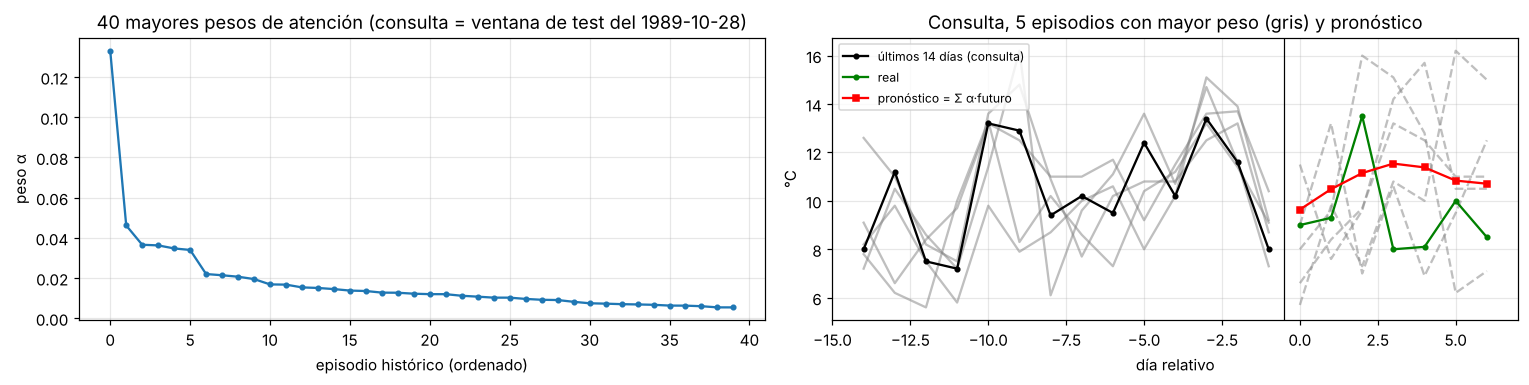

In [6]:
pred_an, W_an = analog_forecast(Xte, data["test"]["dates"], best_tau)
res = {"Atención no paramétrica (NumPy)": {"val": metrics(Yva, analog_forecast(Xva, data["val"]["dates"], best_tau)[0], scaler),
                                            "test": metrics(Yte, pred_an, scaler), "params": 0, "tiempo_s": 0.0}}
j = 300
top = np.argsort(-W_an[j])[:5]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].plot(np.sort(W_an[j])[::-1][:40], "o-", ms=3); ax[0].set_title(f"40 mayores pesos de atención (consulta = ventana de test del {str(data['test']['dates'][j])[:10]})")
ax[0].set_xlabel("episodio histórico (ordenado)"); ax[0].set_ylabel("peso α")
for t in top:
    ax[1].plot(range(-14, 0), scaler.inverse(Xtr[t, -14:, 0]), color="gray", alpha=0.5)
    ax[1].plot(range(0, 7), scaler.inverse(Ytr[t]), color="gray", alpha=0.5, ls="--")
ax[1].plot(range(-14, 0), scaler.inverse(Xte[j, -14:, 0]), "k-o", ms=3, label="últimos 14 días (consulta)")
ax[1].plot(range(0, 7), scaler.inverse(Yte[j]), "g-o", ms=3, label="real")
ax[1].plot(range(0, 7), scaler.inverse(pred_an[j]), "r-s", ms=4, label="pronóstico = Σ α·futuro")
ax[1].axvline(-0.5, c="k", lw=0.8); ax[1].set_xlabel("día relativo"); ax[1].set_ylabel("°C"); ax[1].legend(fontsize=8)
ax[1].set_title("Consulta, 5 episodios con mayor peso (gris) y pronóstico")
plt.tight_layout(); plt.savefig("figures/02_atencion_numpy.png", bbox_inches="tight"); plt.show()

## 2. Modelos neuronales con atención (Keras)

Los tres modelos comparten un LSTM de 64 unidades que recorre los 60 días y produce un estado oculto $h_t$ por día.

| Modelo | Cómo resume la secuencia |
|---|---|
| **LSTM** | Sólo usa el último estado $h_{60}$ (toda la historia debe «caber» en un vector) |
| **LSTM + atención aditiva** | $e_t = v^\top \tanh(W_1 h_t + W_2 h_{60})$, $\alpha = \mathrm{softmax}(e)$, contexto $c = \sum_t \alpha_t h_t$ |
| **LSTM + atención producto escalado** | $\alpha = \mathrm{softmax}(q K^\top/\sqrt{d})$ con $q = W_q h_{60}$, $K = W_k H$, $V = W_v H$ |

En los dos últimos, la salida concatena el contexto $c$ y el último estado y una capa densa produce los 7 días.

In [7]:
def build_lstm():
    x = keras.Input((LOOKBACK, 3), name="ventana")
    h = layers.LSTM(64, name="lstm")(x)
    return keras.Model(x, layers.Dense(HORIZON, name="pronostico")(layers.Dropout(0.2)(h)), name="LSTM")

def build_lstm_additive():
    x = keras.Input((LOOKBACK, 3), name="ventana")
    H, h_last, _ = layers.LSTM(64, return_sequences=True, return_state=True, name="lstm")(x)
    context, alpha = AdditiveAttention(32, name="atencion_aditiva")(H, h_last)
    z = layers.Concatenate()([context, h_last])
    y = layers.Dense(HORIZON, name="pronostico")(layers.Dropout(0.2)(z))
    return keras.Model(x, y, name="LSTM_atencion_aditiva"), keras.Model(x, alpha)

@keras.saving.register_keras_serializable(package="tst")
class DotProductAttentionPool(layers.Layer):
    """Una consulta (último estado) atiende a todos los estados: softmax(q·Kᵀ/√d)·V."""
    def __init__(self, d=32, **kw):
        super().__init__(**kw); self.d = d
        self.wq, self.wk, self.wv = layers.Dense(d), layers.Dense(d), layers.Dense(d)
    def call(self, H, h_last):
        q = ops.expand_dims(self.wq(h_last), 1)                              # (B, 1, d)
        ctx, w = scaled_dot_product_attention(q, self.wk(H), self.wv(H))   # (B, 1, d), (B, 1, T)
        return ops.squeeze(ctx, 1), ops.squeeze(w, 1)
    def get_config(self): return {**super().get_config(), "d": self.d}

def build_lstm_dot():
    x = keras.Input((LOOKBACK, 3), name="ventana")
    H, h_last, _ = layers.LSTM(64, return_sequences=True, return_state=True, name="lstm")(x)
    context, alpha = DotProductAttentionPool(32, name="atencion_producto")(H, h_last)
    y = layers.Dense(HORIZON, name="pronostico")(layers.Dropout(0.2)(layers.Concatenate()([context, h_last])))
    return keras.Model(x, y, name="LSTM_atencion_producto"), keras.Model(x, alpha)

def fit(model, epochs=150, lr=1e-3, batch=64):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse", metrics=["mae"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=epochs, batch_size=batch, callbacks=cb, verbose=0)
    return {k: [float(v) for v in vals] for k, vals in h.history.items()}, time.time() - t0

In [8]:
models, att_models, hists = {}, {}, {}
for name, builder in [("LSTM", build_lstm), ("LSTM + atención aditiva", build_lstm_additive), ("LSTM + atención producto escalado", build_lstm_dot)]:
    keras.utils.set_random_seed(SEED)
    out = builder()
    m, a = (out if isinstance(out, tuple) else (out, None))
    hists[name], secs = fit(m)
    models[name], att_models[name] = m, a
    res[name] = {"val": metrics(Yva, m.predict(Xva, verbose=0), scaler), "test": metrics(Yte, m.predict(Xte, verbose=0), scaler),
                 "params": m.count_params(), "tiempo_s": round(secs, 1), "epocas": len(hists[name]["loss"])}
    print(f"{name:<36} params={m.count_params():6d} épocas={len(hists[name]['loss']):3d} tiempo={secs:5.1f}s "
          f"MAE val={res[name]['val']['MAE']:.3f} test={res[name]['test']['MAE']:.3f} °C")
models["LSTM + atención aditiva"].summary()

LSTM                                 params= 17863 épocas= 45 tiempo= 29.1s MAE val=2.159 test=1.987 °C


LSTM + atención aditiva              params= 22471 épocas= 27 tiempo= 26.0s MAE val=2.170 test=1.981 °C


LSTM + atención producto escalado    params= 24327 épocas= 33 tiempo= 32.6s MAE val=2.146 test=1.989 °C


Model: "LSTM_atencion_aditiva"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ventana             │ (None, 60, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 60, 64),  │     17,408 │ ventana[0][0]     │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atencion_aditiva    │ [(None, 64),      │      4,160 │ lstm[0][0],       │
│ (AdditiveAttention) │ (None, 60)]       │            │ lstm[0][1]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ atencion_aditiva… │
│ (Concatenate)       │                   │            │ lstm[0][1]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pronostico (Dense)  │ (None, 7)         │        903 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 67,415 (263.34 KB)

 Trainable params: 22,471 (87.78 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,944 (175.57 KB)

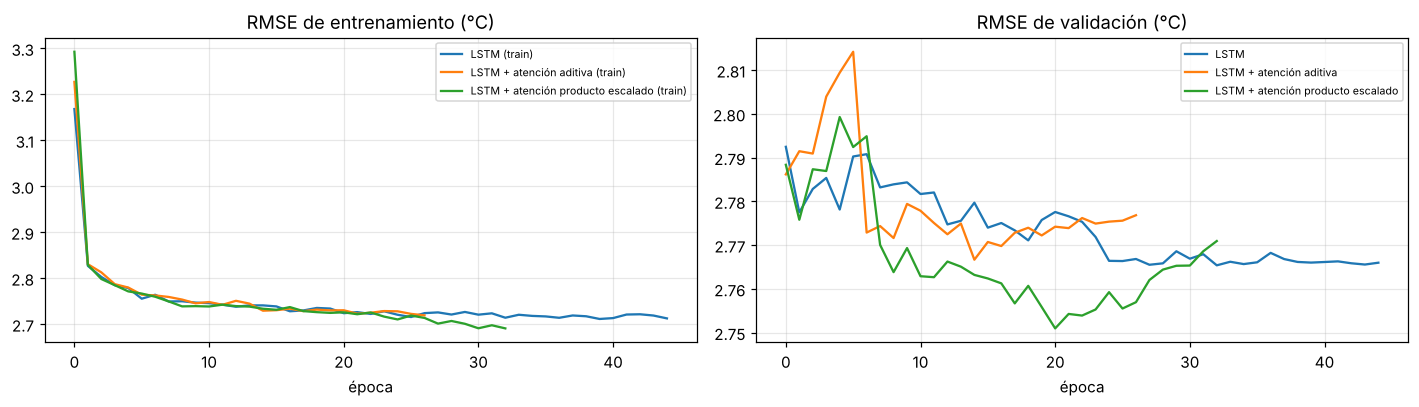

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, h in hists.items():
    ax[0].plot(np.sqrt(h["loss"]) * scaler.sigma, label=f"{name} (train)")
    ax[1].plot(np.sqrt(h["val_loss"]) * scaler.sigma, label=name)
ax[0].set_title("RMSE de entrenamiento (°C)"); ax[1].set_title("RMSE de validación (°C)")
for a in ax: a.set_xlabel("época"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/02_entrenamiento.png", bbox_inches="tight"); plt.show()

## 3. Resultados en test

In [10]:
rows = {}
for n, v in {**{k: {"test": base[k]["test"]} for k in base}, **res}.items():
    rows[n] = {"MAE test (°C)": v["test"]["MAE"], "RMSE test (°C)": v["test"]["RMSE"], "MAE día 1": v["test"]["MAE_d1"],
               "MAE día 7": v["test"]["MAE_d7"], "parámetros": res.get(n, {}).get("params", np.nan)}
comp = pd.DataFrame(rows).T
comp.round(3)

,MAE test (°C),RMSE test (°C),MAE día 1,MAE día 7,parámetros
Persistencia,2.624,3.321,1.958,2.750,NaN
Climatología,2.024,2.593,2.031,2.014,NaN
Regresión lineal (Ridge),1.994,2.568,1.765,2.026,NaN
Atención no paramétrica (NumPy),1.990,2.544,1.862,2.027,0.0
LSTM,1.987,2.540,1.822,2.011,17863.0
LSTM + atención aditiva,1.981,2.536,1.866,1.992,22471.0
LSTM + atención producto escalado,1.989,2.549,1.835,2.016,24327.0


## 4. ¿A qué días del pasado atiende el modelo?
Los pesos α del modelo con atención aditiva se promedian sobre todas las ventanas de test. El eje x es el rezago: 1 = ayer, 60 = hace 60 días.

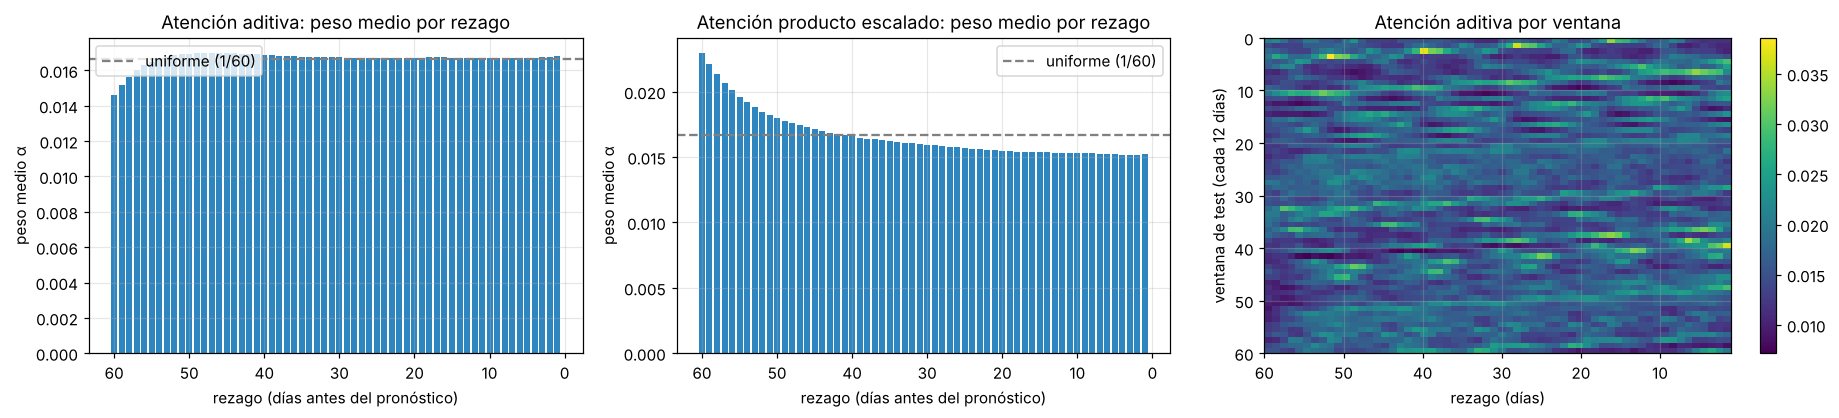

Fracción de la atención en los últimos 7 días: {'aditiva': 0.117, 'producto': 0.106} (uniforme = 0.117)


In [11]:
alpha_add = att_models["LSTM + atención aditiva"].predict(Xte, verbose=0)
alpha_dot = att_models["LSTM + atención producto escalado"].predict(Xte, verbose=0)
lag = np.arange(LOOKBACK, 0, -1)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1.1, 1.1, 1.3]})
for a_, alpha, nm in [(ax[0], alpha_add, "aditiva"), (ax[1], alpha_dot, "producto escalado")]:
    a_.bar(lag, alpha.mean(0), color="#2e86c1"); a_.axhline(1 / LOOKBACK, ls="--", c="gray", label="uniforme (1/60)")
    a_.set_xlabel("rezago (días antes del pronóstico)"); a_.set_ylabel("peso medio α"); a_.set_title(f"Atención {nm}: peso medio por rezago"); a_.legend()
    a_.invert_xaxis()
im = ax[2].imshow(alpha_add[::12][:60], aspect="auto", cmap="viridis", extent=[LOOKBACK, 1, 60, 0])
ax[2].set_xlabel("rezago (días)"); ax[2].set_ylabel("ventana de test (cada 12 días)"); ax[2].set_title("Atención aditiva por ventana")
plt.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.savefig("figures/02_pesos_atencion.png", bbox_inches="tight"); plt.show()
share7 = {nm: float(a[:, -7:].sum(1).mean()) for nm, a in [("aditiva", alpha_add), ("producto", alpha_dot)]}
print("Fracción de la atención en los últimos 7 días:", {k: round(v, 3) for k, v in share7.items()}, "(uniforme = 0.117)")

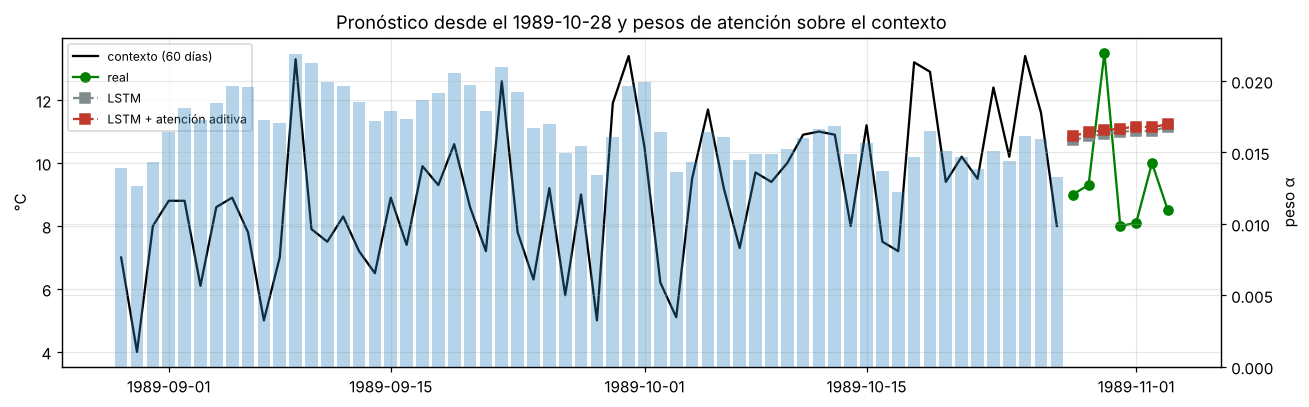

In [12]:
j = 300
d0 = pd.Timestamp(data["test"]["dates"][j])
fig, ax1 = plt.subplots(figsize=(12, 3.8))
past = pd.date_range(end=d0 - pd.Timedelta(days=1), periods=LOOKBACK); fut = pd.date_range(d0, periods=HORIZON)
ax1.plot(past, scaler.inverse(Xte[j, :, 0]), "k-", label="contexto (60 días)")
ax1.plot(fut, scaler.inverse(Yte[j]), "g-o", label="real")
for n, c in [("LSTM", "#7f8c8d"), ("LSTM + atención aditiva", "#c0392b")]:
    ax1.plot(fut, scaler.inverse(models[n].predict(Xte[j:j + 1], verbose=0)[0]), "s--", c=c, label=n)
ax2 = ax1.twinx(); ax2.bar(past, alpha_add[j], color="#2e86c1", alpha=0.35, label="α (aditiva)"); ax2.set_ylabel("peso α")
ax1.set_ylabel("°C"); ax1.set_title(f"Pronóstico desde el {d0.date()} y pesos de atención sobre el contexto")
ax1.legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.savefig("figures/02_ejemplo.png", bbox_inches="tight"); plt.show()

In [13]:
for n, m in models.items():
    m.save(f"modelos/{m.name}.keras")
save_json({"resultados": res, "tau": best_tau, "atencion_ultimos7": share7, "alpha_medio_aditiva": alpha_add.mean(0),
           "alpha_medio_producto": alpha_dot.mean(0), "historias": hists}, "results/02_atencion.json")

## 5. Conclusiones
* **Atención no paramétrica (NumPy):** con τ = 0.2 cada pronóstico promedia de forma ponderada unos 170 episodios históricos parecidos y alcanza MAE 1.99 °C, igual a la regresión lineal, sin ningún parámetro entrenable. Muestra la esencia del mecanismo: consulta, claves, valores y pesos softmax.
* **Modelos neuronales:** los tres LSTM quedan en 1.98–1.99 °C; la atención aditiva logra el mejor MAE de este grupo (1.981 °C) y el mejor error a 7 días (1.99 °C), pero la diferencia frente al LSTM simple (1.987 °C) es pequeña. En el día 1 ninguno supera a la regresión lineal (1.77 °C).
* **Pesos de atención:** en promedio son casi uniformes (el 11.7 % de la atención cae en los últimos 7 días, igual que una distribución uniforme). El LSTM ya resume la información reciente en su último estado, que se concatena al contexto, así que la atención actúa sobre todo como un **promedio global de la ventana**. El mapa por ventana muestra que en cada caso concreto sí se concentra en días específicos, de modo que la ponderación depende del contenido y no sólo de la posición.
* Conclusión: el mecanismo de atención funciona y es interpretable, pero en una serie con memoria corta su beneficio sobre un buen modelo recurrente es marginal. Su ventaja estructural (acceso directo a cualquier día del contexto) se aprovecha mejor dentro del Transformer.